[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Naviden/Introduction-to-XAI/blob/main/Tools/InterpretableModels_examples/Interpretable_Models_Comparison.ipynb)

[Colab setup: dependencies and repository files](https://github.com/Naviden/Introduction-to-XAI/blob/main/docs/REPRODUCIBILITY.md#google-colab)

**Validated reading copy.** Run the [source notebook](../../../../Tools/InterpretableModels_examples/Interpretable_Models_Comparison.ipynb) in its original directory. This snapshot includes checked outputs; source SHA-256: `8df7798207c713c2a6c42192fcd0b88aa129da4409276b4a9ee4f0091c413029`. Timings describe this recorded environment, not a performance guarantee.

# Compare intrinsically interpretable models before adding an explainer

**Question:** can a model's own structure provide a useful explanation at acceptable predictive performance?

Compare **logistic regression**, a **small decision tree**, an **additive spline logistic model**, two **Explainable Boosting Machines (EBMs)** and a **random forest** on the same six inputs and stratified train/test split. The forest is a predictive reference; the other models are trained directly on the true labels, **not as surrogates of the forest**.

- **Prerequisites:** classification metrics, train/test splits, log-odds. Install `requirements-tabular.txt` from the repository root.
- **Resources:** bundled data, CPU only, no model downloads, Java or neural frameworks. The EBM implementation is `interpret-core==0.7.8`, the minimal native-model package pinned in `requirements-tabular.txt`; no dashboard extras are needed.
- **Learning goals:** inspect coefficients, trace a decision path, read additive shape functions, and reconstruct local predictions exactly.
- **Limits:** one small dataset and one split cannot establish a universal accuracy–interpretability tradeoff. These examples describe model behavior, not clinical decisions or causal effects.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import subprocess
from interpret.glassbox import ExplainableBoostingClassifier
import time
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print({name: metadata.version(name) for name in ['numpy', 'scipy', 'scikit-learn', 'interpret-core']})
ROOT = Path.cwd().resolve().parents[1]
OUTPUT = ROOT / 'validation' / 'interpretable-models'
OUTPUT.mkdir(parents=True, exist_ok=True)

{'numpy': '2.4.6', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'interpret-core': '0.7.8'}


## Same inputs and split for every model

Use six **preselected** measurements to keep coefficients and shape curves readable. This is a teaching subset, not a feature set optimized against test outcomes. Several inputs are correlated; a readable model still need not identify a unique causal or stable effect. The held-out partition is used only for reporting and illustrative explanations.

In [2]:
dataset = load_breast_cancer(as_frame=True)
features = ['mean radius', 'mean texture', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean symmetry']
X = dataset.data.loc[:, features].copy()
y = (dataset.target == 0).astype(int).rename('malignant')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
print(f'{len(X_train)} training cases; {len(X_test)} held-out cases; malignant = 1')
display(X_train.corr().round(2))

426 training cases; 143 held-out cases; malignant = 1


,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean symmetry
mean radius,1.00,0.31,0.18,0.51,0.66,0.11
mean texture,0.31,1.00,-0.05,0.20,0.25,0.05
mean smoothness,0.18,-0.05,1.00,0.67,0.54,0.56
mean compactness,0.51,0.20,0.67,1.00,0.89,0.59
mean concavity,0.66,0.25,0.54,0.89,1.00,0.50
mean symmetry,0.11,0.05,0.56,0.59,0.50,1.00


## Define model capacity before viewing test results

Logistic regression is additive and linear in **log-odds**. The spline model replaces each linear term with a learned smooth function:

\[
\log\frac{p(x)}{1-p(x)} = \beta_0 + \sum_j f_j(x_j).
\]

Each feature gets its **own** spline basis; there are no cross-feature products. Logistic regression fits all basis coefficients jointly with L2 regularization. This is a simple generalized additive model with a logistic link, **not the Explainable Boosting Machine algorithm**. Its knots are learned only from training data. Fixed settings keep this exercise small; a real model-selection study should use training-only cross-validation and an untouched final test set.

The **EBM is a different fitted model**: it learns binned feature functions by boosting, with bagging and optional interaction terms. We fit an additive EBM (`interactions=0`) and an EBM with two pairwise terms selected from training data. Both use bounded settings declared below. Internal validation for early stopping uses only the training partition; the final test partition is never passed to `fit`. These capacities are illustrative rather than equally optimized computational budgets. More interactions add structures that a reader must inspect.


In [3]:
spline_terms = [(f'feature_{j}', SplineTransformer(n_knots=4, degree=3, knots='quantile',
                                                include_bias=False, extrapolation='constant'), [name])
                for j, name in enumerate(features)]
models = {
    'Logistic regression': Pipeline([('scale', StandardScaler()),
                                     ('classifier', LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))]),
    'Small decision tree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=12, random_state=SEED),
    'Additive spline logistic': Pipeline([('basis', ColumnTransformer(spline_terms)),
                                          ('classifier', LogisticRegression(C=0.5, max_iter=2000, random_state=SEED))]),
    'EBM additive': ExplainableBoostingClassifier(interactions=0, max_bins=64, outer_bags=4,
                                                   max_rounds=500, early_stopping_rounds=50,
                                                   n_jobs=1, random_state=SEED),
    'EBM with 2 interactions': ExplainableBoostingClassifier(interactions=2, max_bins=64, max_interaction_bins=16,
                                                              outer_bags=4, max_rounds=500, early_stopping_rounds=50,
                                                              n_jobs=1, random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=2,
                                            n_jobs=2, random_state=SEED),
}
records = []
for name, estimator in models.items():
    started = time.perf_counter()
    estimator.fit(X_train, y_train)
    seconds = time.perf_counter() - started
    assert np.array_equal(estimator.classes_, [0, 1])
    probability = estimator.predict_proba(X_test)[:, 1]
    records.append({'model': name, 'ROC AUC (higher better)': roc_auc_score(y_test, probability),
                    'balanced accuracy (higher better)': balanced_accuracy_score(y_test, estimator.predict(X_test)),
                    'Brier loss (lower better)': brier_score_loss(y_test, probability),
                    'log loss (lower better)': log_loss(y_test, probability), 'fit seconds': seconds})
metrics = pd.DataFrame(records).set_index('model')
display(metrics.round(4))

,ROC AUC (higher better),balanced accuracy (higher better),Brier loss (lower better),log loss (lower better),fit seconds
model,,,,,
Logistic regression,0.9857,0.9251,0.0454,0.1469,0.0030
Small decision tree,0.9368,0.8834,0.0713,0.4774,0.0008
Additive spline logistic,0.9887,0.9229,0.0495,0.1845,0.0052
EBM additive,0.9885,0.9323,0.0382,0.1299,0.1167
EBM with 2 interactions,0.9914,0.9512,0.0340,0.1206,0.1470
Random forest,0.9870,0.9212,0.0463,0.1639,0.0497


## Predictive performance and structural complexity

AUC describes ranking, balanced accuracy uses the default 0.5 decision threshold, and the two losses assess probability predictions. They answer different questions. Structural counts below are descriptive: a coefficient, a smooth curve and a tree node are **not equivalent units of human effort**. The table and plots are a comparison of these fitted models, not a leaderboard.

,structure to inspect,interactions
model,,
Logistic regression,6 linear terms + intercept,none in log-odds
Small decision tree,13 nodes / 7 leaves,conditions along paths
Additive spline logistic,6 curves / 30 spline coefficients + intercept,none in log-odds
EBM additive,6 learned binned functions + intercept,none in log-odds
EBM with 2 interactions,8 learned term functions + intercept,two learned pairwise surfaces
Random forest,100 trees / 3334 total nodes,conditions across many trees


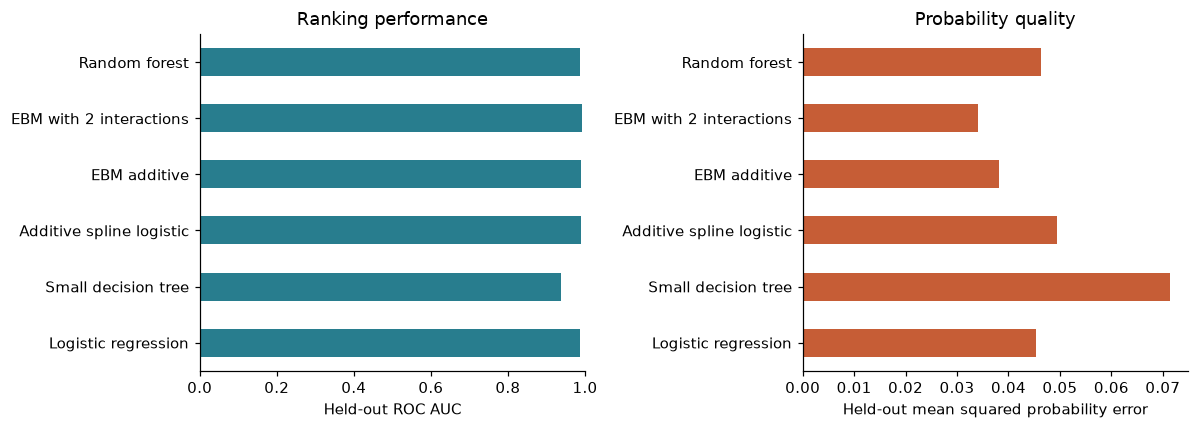

In [4]:
logistic = models['Logistic regression']
tree = models['Small decision tree']
additive = models['Additive spline logistic']
forest = models['Random forest']
complexity = pd.DataFrame([
    {'model': 'Logistic regression', 'structure to inspect': f'{len(features)} linear terms + intercept', 'interactions': 'none in log-odds'},
    {'model': 'Small decision tree', 'structure to inspect': f'{tree.tree_.node_count} nodes / {tree.get_n_leaves()} leaves', 'interactions': 'conditions along paths'},
    {'model': 'Additive spline logistic', 'structure to inspect': f'{len(features)} curves / {additive.named_steps["classifier"].coef_.size} spline coefficients + intercept', 'interactions': 'none in log-odds'},
    {'model': 'EBM additive', 'structure to inspect': f'{len(models["EBM additive"].term_features_)} learned binned functions + intercept', 'interactions': 'none in log-odds'},
    {'model': 'EBM with 2 interactions', 'structure to inspect': f'{len(models["EBM with 2 interactions"].term_features_)} learned term functions + intercept', 'interactions': 'two learned pairwise surfaces'},
    {'model': 'Random forest', 'structure to inspect': f'{len(forest.estimators_)} trees / {sum(t.tree_.node_count for t in forest.estimators_)} total nodes', 'interactions': 'conditions across many trees'},
]).set_index('model')
display(complexity)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metrics['ROC AUC (higher better)'].plot.barh(ax=axes[0], color='#287D8E')
axes[0].set(xlim=(0, 1), xlabel='Held-out ROC AUC', ylabel='', title='Ranking performance')
metrics['Brier loss (lower better)'].plot.barh(ax=axes[1], color='#C65D36')
axes[1].set(xlabel='Held-out mean squared probability error', ylabel='', title='Probability quality')
fig.tight_layout()
plt.show()

## Logistic regression: global coefficients and a local decomposition

Standardization uses training means and standard deviations. A coefficient is the log-odds change for one training standard deviation in that input, with the other inputs held fixed. This is a statement about the fitted model. Correlation, regularization and the chosen inputs affect coefficients, so a small or negative coefficient is not evidence of a protective real-world intervention.

The intercept is the prediction's log-odds at the training means. For a fixed case, each coefficient multiplied by its standardized input is an **exact model contribution in log-odds**. Applying the sigmoid converts the reconstructed total to a probability; individual log-odds contributions do not add in probability units.

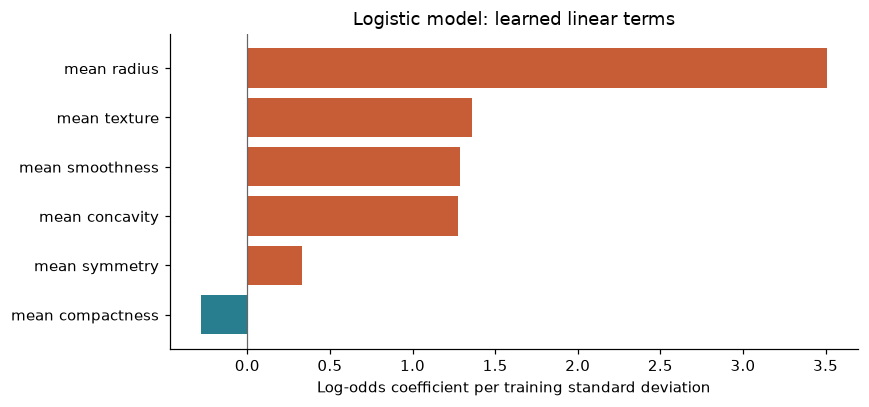

Case: original dataset row 12; observed malignant label: 1


,local log-odds contribution
mean radius,4.903889
mean texture,1.714318
mean smoothness,0.125892
mean compactness,-0.758016
mean concavity,1.852840
mean symmetry,0.708970


Intercept -0.7193 + contributions 8.5479 = logit 7.8286; P(malignant) = 0.9996


In [5]:
coefficients = pd.Series(logistic.named_steps['classifier'].coef_[0], index=features)
fig, ax = plt.subplots(figsize=(8, 3.8))
ordered = coefficients.sort_values()
ax.barh(ordered.index, ordered.values, color=['#287D8E' if v < 0 else '#C65D36' for v in ordered])
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(xlabel='Log-odds coefficient per training standard deviation', title='Logistic model: learned linear terms')
fig.tight_layout()
plt.show()

# Fixed by test-row position, rather than selected for a convincing explanation.
query = X_test.iloc[[0]]
standardized_query = logistic.named_steps['scale'].transform(query)[0]
linear_contributions = standardized_query * coefficients.to_numpy()
linear_baseline = float(logistic.named_steps['classifier'].intercept_[0])
linear_logit = float(linear_baseline + linear_contributions.sum())
np.testing.assert_allclose(linear_logit, logistic.decision_function(query)[0], atol=1e-10)
np.testing.assert_allclose(expit(linear_logit), logistic.predict_proba(query)[0, 1], atol=1e-10)
print(f'Case: original dataset row {query.index[0]}; observed malignant label: {y_test.iloc[0]}')
display(pd.Series(linear_contributions, index=features, name='local log-odds contribution').to_frame())
print(f'Intercept {linear_baseline:.4f} + contributions {linear_contributions.sum():.4f} = logit {linear_logit:.4f}; P(malignant) = {expit(linear_logit):.4f}')

## Small decision tree: follow the actual rules

Each internal node tests one input. A case follows exactly one path to a leaf; the leaf's class proportions determine this tree's probability. The rules belong to the fitted predictor itself, so there is no separate surrogate-fidelity gap. A shallow tree can still be inaccurate or unstable, and its thresholds are statistical splits, not clinical cutoffs.

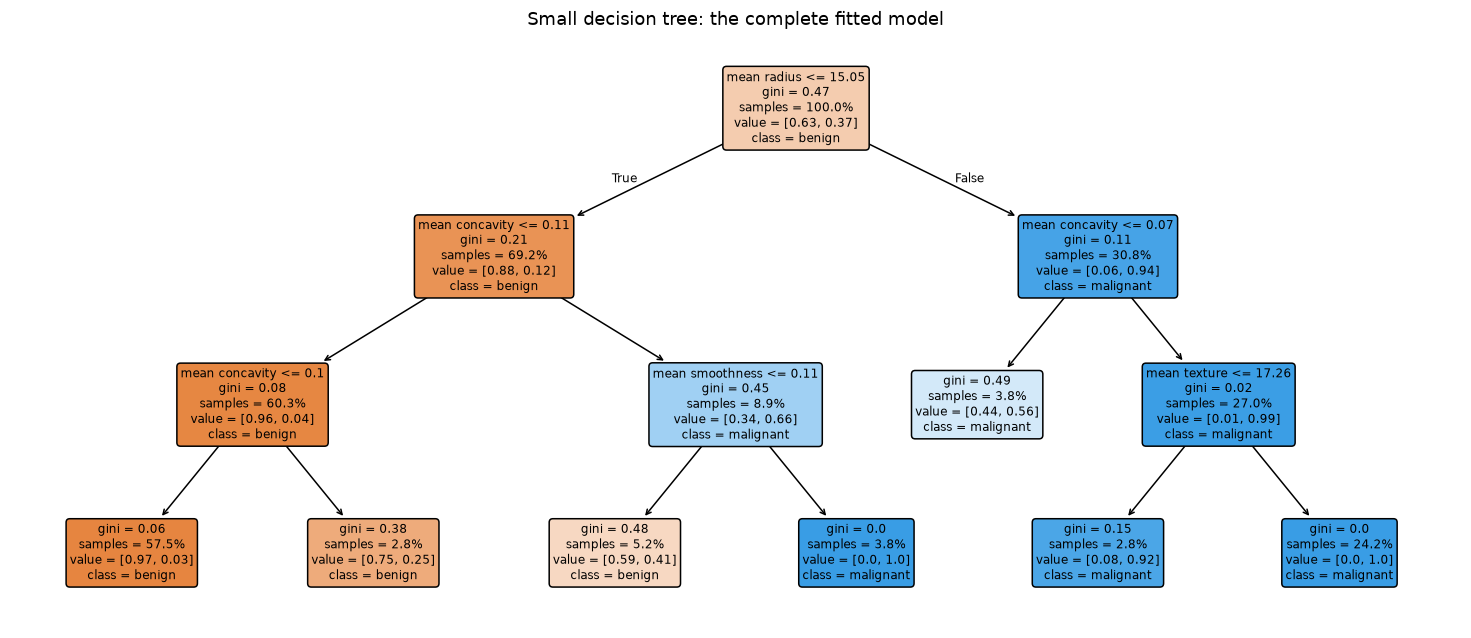

,node,feature,case value,condition followed
0,0,mean radius,19.1700,> 15.045
1,8,mean concavity,0.2065,> 0.07214
2,10,mean texture,24.8000,> 17.26


Leaf 12; tree P(malignant): 1.0000


In [6]:
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(tree, feature_names=features, class_names=['benign', 'malignant'], filled=True, rounded=True,
          proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title('Small decision tree: the complete fitted model')
plt.show()

path = tree.decision_path(query).indices
leaf = int(tree.apply(query)[0])
path_rows = []
for node in path:
    if node == leaf:
        continue
    feature_index = tree.tree_.feature[node]
    threshold = tree.tree_.threshold[node]
    value = float(query.iloc[0, feature_index])
    path_rows.append({'node': int(node), 'feature': features[feature_index], 'case value': value,
                      'condition followed': f'<= {threshold:.6g}' if value <= threshold else f'> {threshold:.6g}'})
display(pd.DataFrame(path_rows))
print(f'Leaf {leaf}; tree P(malignant): {tree.predict_proba(query)[0, 1]:.4f}')

## Additive spline model: inspect the learned functions

For readability, center each feature's learned function over the **training cases** and move those means into the intercept. This changes presentation but leaves predictions unchanged. The centered function can be written as

\[
\widetilde f_j(x_j)=f_j(x_j)-\frac{1}{n_{train}}\sum_{i\in train} f_j(x_{ij}).
\]

A curve shows the model's own term in log-odds. It is not a fitted explanation of another model. Quantile knots and regularization constrain the curves, but correlated inputs can still share effects in unstable ways. We show only each feature's training 2nd–98th percentile range and include observed-value ticks. The chosen constant extrapolation does not make predictions beyond observed support trustworthy.

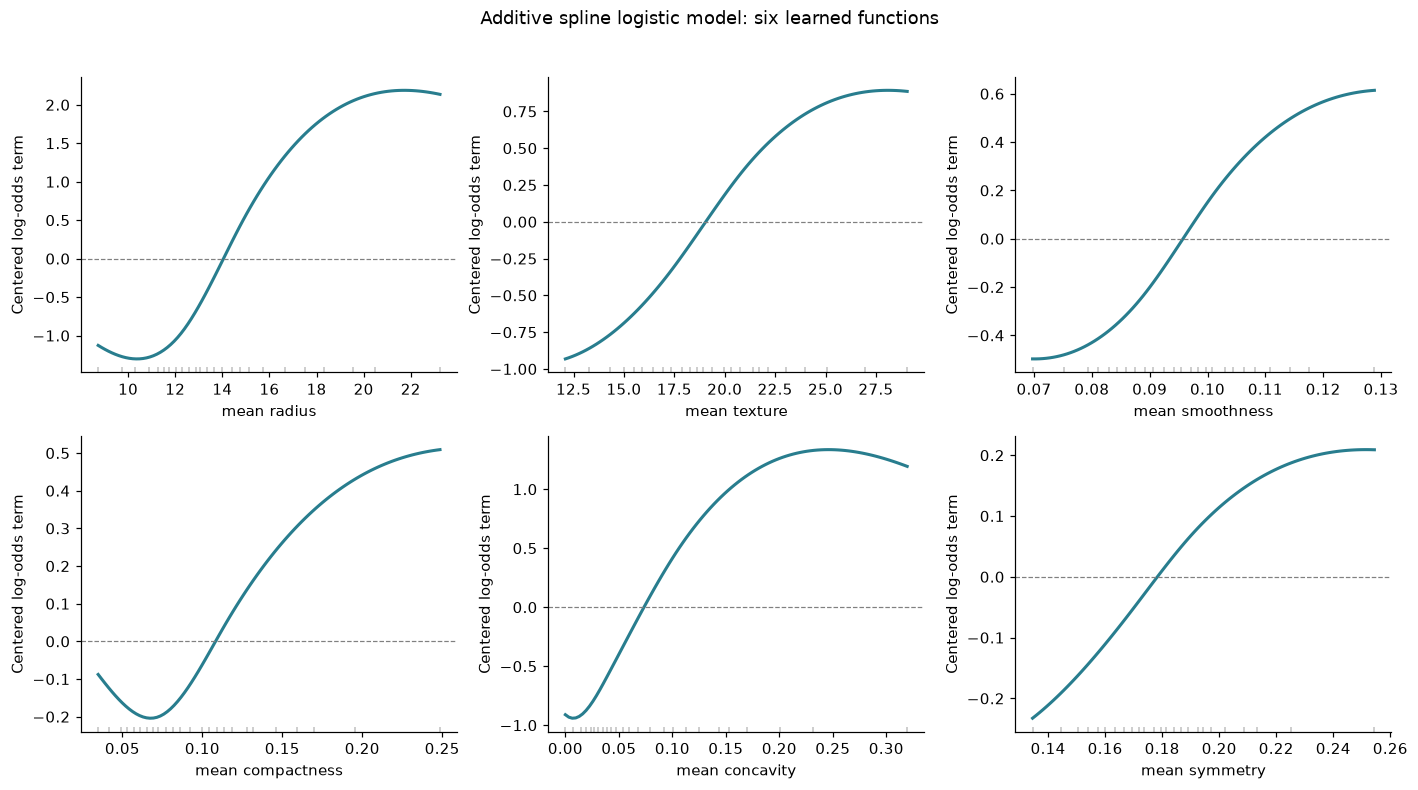

In [7]:
basis = additive.named_steps['basis']
additive_classifier = additive.named_steps['classifier']
additive_coefficients = additive_classifier.coef_[0]
term_slices = [basis.output_indices_[f'feature_{j}'] for j in range(len(features))]

def raw_additive_terms(frame):
    transformed = basis.transform(frame)
    return np.column_stack([transformed[:, block] @ additive_coefficients[block] for block in term_slices])

training_term_means = raw_additive_terms(X_train).mean(axis=0)
additive_baseline = float(additive_classifier.intercept_[0] + training_term_means.sum())
# Verify both training and held-out rows, not just the displayed example.
for frame in [X_train, X_test]:
    centered_terms = raw_additive_terms(frame) - training_term_means
    np.testing.assert_allclose(additive_baseline + centered_terms.sum(axis=1), additive.decision_function(frame), atol=1e-10)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, (feature, ax) in enumerate(zip(features, axes.flat)):
    grid = np.linspace(*X_train[feature].quantile([0.02, 0.98]).to_numpy(), 100)
    # Other feature values do not affect this term, because the basis has no interactions.
    grid_frame = pd.DataFrame(np.tile(X_train.mean().to_numpy(), (len(grid), 1)), columns=features)
    grid_frame[feature] = grid
    term = raw_additive_terms(grid_frame)[:, j] - training_term_means[j]
    ax.plot(grid, term, color='#287D8E', linewidth=2)
    ax.axhline(0, color='0.5', linewidth=0.8, linestyle='--')
    ticks = X_train[feature].quantile(np.linspace(0.02, 0.98, 25))
    ax.plot(ticks, np.zeros(len(ticks)), '|', transform=ax.get_xaxis_transform(), color='0.5', alpha=0.5)
    ax.set(xlabel=feature, ylabel='Centered log-odds term')
fig.suptitle('Additive spline logistic model: six learned functions', y=1.02)
fig.tight_layout()
plt.show()

## Explain the same case with the additive model

The baseline below is the training-average **logit** of this additive model. Its sigmoid is not generally the average predicted probability. Each centered curve value contributes exactly to this case's logit. These contributions differ from the linear model's because the fitted functions and reference values differ; they are not SHAP values.

The probability link is nonlinear. Even with no interactions in log-odds, changing a term can change probability by an amount that depends on the other terms.

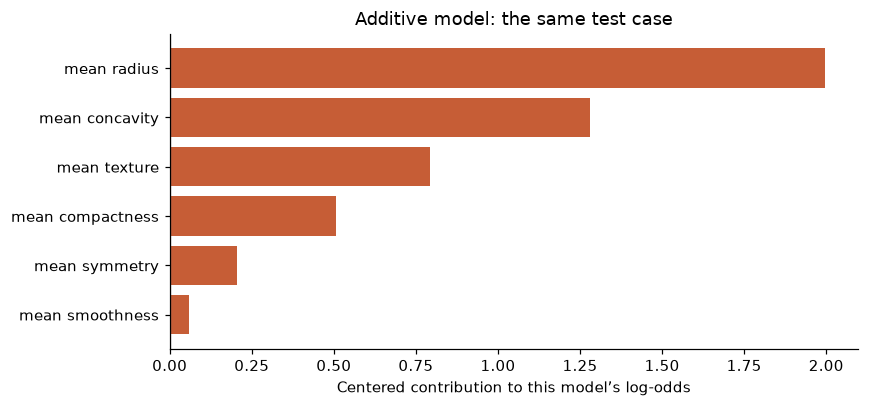

Centered baseline -0.8138 + terms 4.8426 = logit 4.0288; P(malignant) = 0.9825


,same-case P(malignant)
Logistic regression,0.999602
Small decision tree,1.000000
Additive spline logistic,0.982516
EBM additive,0.999923
EBM with 2 interactions,0.999929
Random forest,0.997504


In [8]:
additive_contributions = raw_additive_terms(query)[0] - training_term_means
additive_logit = float(additive_baseline + additive_contributions.sum())
np.testing.assert_allclose(expit(additive_logit), additive.predict_proba(query)[0, 1], atol=1e-10)
fig, ax = plt.subplots(figsize=(8, 3.8))
ordered = pd.Series(additive_contributions, index=features).sort_values()
ax.barh(ordered.index, ordered.values, color=['#287D8E' if v < 0 else '#C65D36' for v in ordered])
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(xlabel='Centered contribution to this model’s log-odds', title='Additive model: the same test case')
fig.tight_layout()
plt.show()
print(f'Centered baseline {additive_baseline:.4f} + terms {additive_contributions.sum():.4f} = logit {additive_logit:.4f}; P(malignant) = {expit(additive_logit):.4f}')
display(pd.Series({name: estimator.predict_proba(query)[0, 1] for name, estimator in models.items()}, name='same-case P(malignant)').to_frame())


## EBM: inspect terms and reconstruct the prediction exactly

An EBM stores a score for each feature bin and, when enabled, for each interaction-bin combination. In binary classification with the logit link,

$$\log\frac{p(x)}{1-p(x)}=\beta_0+\sum_t h_t(x_{S_t}).$$

`eval_terms` returns the actual fitted model's term scores. We reconstruct every training and held-out prediction, check `decision_function`, and apply the sigmoid to recover the malignant-class probability. These are model terms, **not SHAP attributions** or a surrogate explanation.

The intercept is on the log-odds scale. Its sigmoid need not equal the average predicted probability. A pairwise score belongs to the pair; assigning it to either single feature requires another allocation rule. Correlation and the regularization/training choices can change how effects are distributed among terms. Exact reconstruction establishes numerical fidelity to this predictor, not a causal or human-validated interpretation.


EBM additive: intercept -1.3069 + terms 10.7754 = logit 9.4685; P(malignant) = 0.9999
EBM with 2 interactions: intercept -1.4144 + terms 10.9685 = logit 9.5540; P(malignant) = 0.9999


,model,term,feature_count,logit_contribution
0,EBM additive,mean radius,1,5.537583
1,EBM additive,mean texture,1,1.730425
2,EBM additive,mean smoothness,1,0.628580
3,EBM additive,mean compactness,1,-0.065525
4,EBM additive,mean concavity,1,2.250580
5,EBM additive,mean symmetry,1,0.693797
6,EBM with 2 interactions,mean radius,1,5.537583
7,EBM with 2 interactions,mean texture,1,1.730425
8,EBM with 2 interactions,mean smoothness,1,0.628580
9,EBM with 2 interactions,mean compactness,1,-0.065525


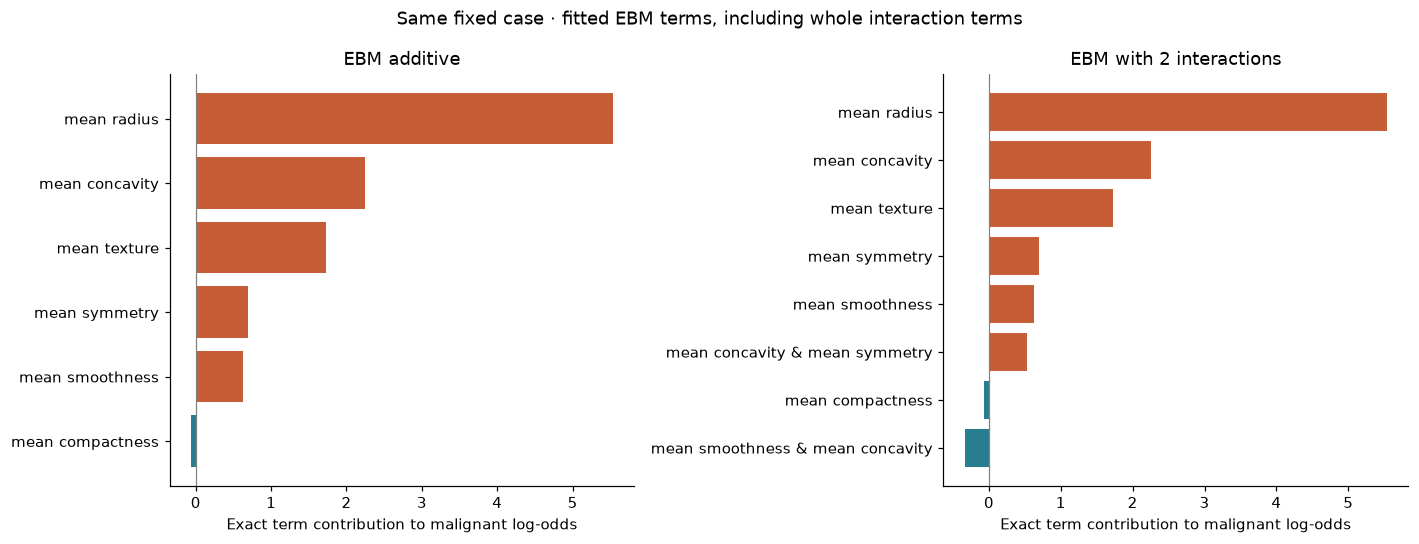

In [9]:

ebm_local_records = []
ebm_validation = []
for model_name in ['EBM additive', 'EBM with 2 interactions']:
    ebm = models[model_name]
    assert ebm.link_ == 'logit' and list(ebm.classes_) == [0, 1]
    intercept = float(np.asarray(ebm.intercept_).ravel()[0])
    for partition, frame in [('train', X_train), ('test', X_test)]:
        terms = ebm.eval_terms(frame)
        reconstructed = intercept + terms.sum(axis=1)
        np.testing.assert_allclose(reconstructed, ebm.decision_function(frame), atol=1e-10)
        np.testing.assert_allclose(expit(reconstructed), ebm.predict_proba(frame)[:, 1], atol=1e-10)
        ebm_validation.append({'model':model_name, 'partition':partition,
                               'max_logit_reconstruction_error':float(np.max(np.abs(reconstructed-ebm.decision_function(frame))))})
    query_terms = ebm.eval_terms(query)[0]
    for term, indices, contribution in zip(ebm.term_names_, ebm.term_features_, query_terms):
        ebm_local_records.append({'model':model_name, 'term':term, 'feature_count':len(indices),
                                  'logit_contribution':float(contribution)})
    print(f'{model_name}: intercept {intercept:.4f} + terms {query_terms.sum():.4f} '
          f'= logit {intercept+query_terms.sum():.4f}; P(malignant) = {expit(intercept+query_terms.sum()):.4f}')
ebm_local = pd.DataFrame(ebm_local_records)
display(ebm_local)
assert all(len(term) == 1 for term in models['EBM additive'].term_features_)
assert sum(len(term) == 2 for term in models['EBM with 2 interactions'].term_features_) == 2

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ['EBM additive', 'EBM with 2 interactions']):
    local = ebm_local[ebm_local.model == name].sort_values('logit_contribution')
    ax.barh(local.term, local.logit_contribution, color=['#287D8E' if v < 0 else '#C65D36' for v in local.logit_contribution])
    ax.axvline(0, color='gray', lw=.8)
    ax.set(title=name, xlabel='Exact term contribution to malignant log-odds')
fig.suptitle('Same fixed case · fitted EBM terms, including whole interaction terms')
fig.tight_layout()
fig.savefig(OUTPUT / 'ebm_local_terms.png', bbox_inches='tight')
plt.show()



## Compare the EBM and spline shapes

The additive EBM and spline model each learn six one-variable functions, using different estimation procedures. For this visual comparison only, subtract each function's training-average value so both vertical axes use centered log-odds contributions. Reassigning those constants to the respective model's intercept leaves its predictions unchanged. This does not make the two models' baselines or predictions identical.

EBM shapes are binned functions, while the spline basis is smooth. Neither visual smoothness nor a visually plausible effect is evidence of accuracy. We show the same training 2nd–98th percentile ranges, without extrapolating the plot. The interaction EBM's two-dimensional surfaces are listed in the local table; they are additional objects a reader must inspect.


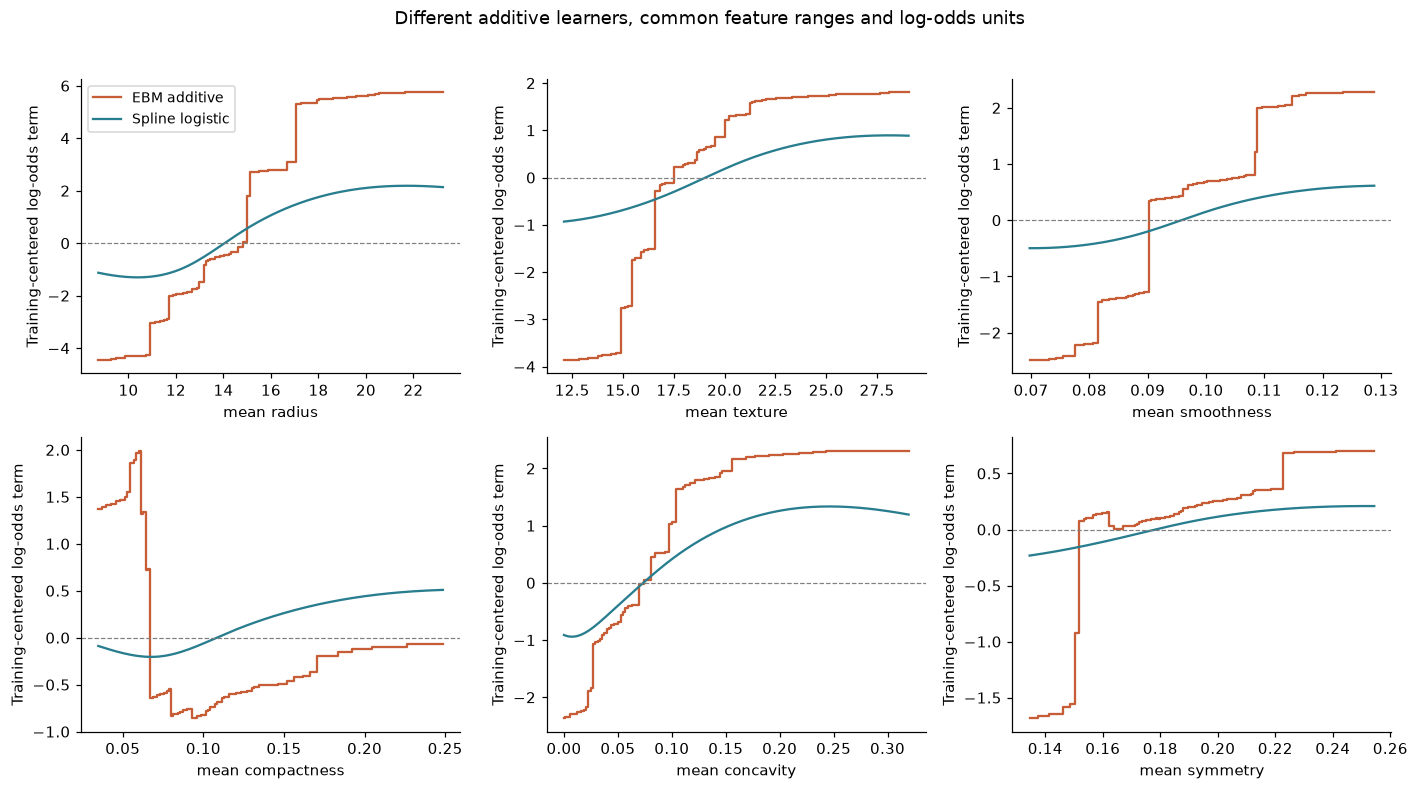

In [10]:

ebm = models['EBM additive']
ebm_training_means = ebm.eval_terms(X_train).mean(axis=0)
ebm_centered_intercept = float(np.asarray(ebm.intercept_).ravel()[0]) + ebm_training_means.sum()
np.testing.assert_allclose(ebm_centered_intercept + (ebm.eval_terms(X_test)-ebm_training_means).sum(axis=1),
                           ebm.decision_function(X_test), atol=1e-10)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, (feature, ax) in enumerate(zip(features, axes.flat)):
    grid = np.linspace(*X_train[feature].quantile([.02, .98]).to_numpy(), 150)
    frame = pd.DataFrame(np.tile(X_train.mean().to_numpy(), (len(grid), 1)), columns=features)
    frame[feature] = grid
    term_index = list(ebm.term_features_).index((j,))
    ax.plot(grid, ebm.eval_terms(frame)[:, term_index]-ebm_training_means[term_index],
            label='EBM additive', color='#C65D36', drawstyle='steps-mid')
    ax.plot(grid, raw_additive_terms(frame)[:, j]-training_term_means[j], label='Spline logistic', color='#287D8E')
    ax.axhline(0, color='gray', lw=.8, linestyle='--')
    ax.set(xlabel=feature, ylabel='Training-centered log-odds term')
axes[0, 0].legend(fontsize=9)
fig.suptitle('Different additive learners, common feature ranges and log-odds units', y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT / 'ebm_spline_shapes.png', bbox_inches='tight')
plt.show()


## Save the comparison and its settings

The record includes fitted model capacities, split and query identities, versions, held-out metrics, and reconstruction checks. These single-split results support this teaching example only.

In [11]:

metrics.to_csv(OUTPUT / 'heldout_metrics.csv')
complexity.to_csv(OUTPUT / 'structural_complexity.csv')
ebm_local.to_csv(OUTPUT / 'ebm_local_terms.csv', index=False)
try:
    commit = subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip()
except (OSError, subprocess.CalledProcessError):
    commit = None
record = dict(schema_version=1, study='Intrinsic model comparison including native EBM', git_commit=commit,
              notebook_sha256=hashlib.sha256(Path('Interpretable_Models_Comparison.ipynb').read_bytes()).hexdigest(),
              seed=SEED, features=features, train_indices=X_train.index.tolist(), test_indices=X_test.index.tolist(),
              query_dataset_index=int(query.index[0]),
              ebm_parameters={name:models[name].get_params() for name in ['EBM additive','EBM with 2 interactions']},
              ebm_reconstruction=ebm_validation,
              versions={name:metadata.version(name) for name in ['numpy','pandas','scipy','scikit-learn','interpret-core']},
              platform=platform.platform(),
              heldout_metrics=json.loads(metrics.reset_index().to_json(orient='records')),
              ebm_local_terms=json.loads(ebm_local.to_json(orient='records')),
              interpretation='Single split with fixed teaching capacities; no universal ranking or causal interpretation.')
(OUTPUT / 'results.json').write_text(json.dumps(record, indent=2, allow_nan=False)+'\n')
print(f'Saved EBM comparison outputs under {OUTPUT}')


Saved EBM comparison outputs under /Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/validation/interpretable-models


## What this comparison does—and does not—show

- A short coefficient table or a small tree can expose the predictor's structure directly. The spline and additive EBM models learn nonlinear terms while retaining six separate curves; the interaction EBM adds two pairwise terms. The forest is much larger to inspect directly.
- Readability does not establish accuracy, stability, fairness, causal meaning or usability for a particular audience. The held-out metrics and structural descriptions must be considered separately.
- Exact reconstruction verifies our decomposition of a fitted model. It does not establish that its features or learned relationships are appropriate.
- The six-feature restriction and fixed capacities are teaching choices. Repeat with training-only model selection, additional datasets/splits and subgroup checks before drawing a broader conclusion.

**Exercises:** refit each model across training resamples and inspect coefficient/curve/split stability; compare the models on a truly interaction-driven synthetic dataset; ask a reader to predict a model's output from its displayed explanation.

## Sources and next steps

- [Scikit-learn: breast-cancer dataset and original references](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).
- [Scikit-learn: interpreting linear-model coefficients](https://scikit-learn.org/stable/auto_examples/inspection/plot_linear_model_coefficient_interpretation.html).
- [Scikit-learn: SplineTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html) and [spline regression example](https://scikit-learn.org/stable/auto_examples/linear_model/plot_polynomial_interpolation.html).
- [Scikit-learn: understanding a decision tree's structure](https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html).
- [InterpretML: Explainable Boosting Machine](https://interpret.ml/docs/ebm.html), [ExplainableBoostingClassifier API](https://interpret.ml/docs/python/api/ExplainableBoostingClassifier.html), and [minimal interpret-core package](https://pypi.org/project/interpret-core/0.7.8/). The native EBM models above use this implementation; interactive dashboard extras are unnecessary.
- Continue with the [lightweight post-hoc starter](../../../../Tools/Starter_examples/First_XAI_Comparison.ipynb) or the [complete shared-case comparison](../../../../Tools/MethodComparison_examples/Shared_Tabular_Case_Comparison.ipynb).